# Bài 5: Thiết lập ARIMA – Dự đoán – Đánh giá

**Dataset:** AirPassengers (144 tháng, 1949–1960) · **Thư viện:** `pandas`, `statsmodels` (class `ARIMA`), `matplotlib`, `sklearn.metrics`

**Quy tắc áp dụng:** chỉ `fit` trên tập Train; tập Test chỉ dùng ở bước dự báo và đánh giá (chống rò rỉ dữ liệu); không shuffle.
Các hàm nằm trong `src/lab02_utils/modeling.py`, notebook này chỉ gọi hàm và trình bày kết quả.

In [1]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split

# Định vị thư mục gốc dự án để import được module từ src/
project_root = Path(os.getcwd())
while project_root.name != '' and not (project_root / 'src').exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.data_loader import load_and_prep_data
from src.lab02_utils.modeling import (fit_arima, residual_diagnostics,
                                      forecast_test, evaluate_forecast, plot_forecast)

plt.style.use('seaborn-v0_8-whitegrid')

# Thư mục lưu ảnh của Lab 02
fig_dir = project_root / 'reports' / 'figures' / 'lab02'
fig_dir.mkdir(parents=True, exist_ok=True)

## Bước 1: Chia Train (80%) / Test (20%), giữ nguyên thứ tự thời gian

In [2]:
processed_dir = project_root / 'data' / 'processed' / 'lab02'
train_file = processed_dir / 'train_data.csv'
test_file = processed_dir / 'test_data.csv'

if train_file.exists() and test_file.exists():
    # Dùng lại đúng tập Train/Test đã xuất ở Bài 1
    train_df = pd.read_csv(train_file, parse_dates=['Month'], index_col='Month')
    test_df = pd.read_csv(test_file, parse_dates=['Month'], index_col='Month')
else:
    # Chưa chạy Bài 1: tự chia lại theo đúng luật (shuffle=False) rồi lưu ra data/processed/lab02/
    df = load_and_prep_data(str(project_root / 'data' / 'raw' / 'AirPassengers.csv'), date_col='Month')
    train_df, test_df = train_test_split(df, test_size=0.2, shuffle=False)
    processed_dir.mkdir(parents=True, exist_ok=True)
    train_df.to_csv(train_file)
    test_df.to_csv(test_file)

# Gán tần suất tháng để statsmodels sinh index dự báo đúng
train = train_df['Passengers'].asfreq('MS')
test = test_df['Passengers'].asfreq('MS')

print(f"Train: {len(train)} quan sát ({train.index.min():%m/%Y} - {train.index.max():%m/%Y})")
print(f"Test : {len(test)} quan sát ({test.index.min():%m/%Y} - {test.index.max():%m/%Y})")

Train: 115 quan sát (01/1949 - 07/1958)
Test : 29 quan sát (08/1958 - 12/1960)


**Nhận xét:** Train có 115 tháng (01/1949 – 07/1958), Test có 29 tháng (08/1958 – 12/1960), Test nằm hoàn toàn *sau* Train về thời gian.

## Bước 2: Thiết lập và fit mô hình ARIMA trên tập Train

Hai mô hình đề xuất lấy theo ví dụ của đề bài: **ARIMA(1,1,1)** và **ARIMA(2,1,1)**, cùng d = 1 (sai phân bậc 1 ở Bài 3).
Bộ (p, q) này cần được đối chiếu lại với ACF/PACF của chuỗi sai phân ở Bài 4.

In [3]:
orders = {'ARIMA(1,1,1)': (1, 1, 1), 'ARIMA(2,1,1)': (2, 1, 1)}
models = {name: fit_arima(train, order) for name, order in orders.items()}

info = pd.DataFrame({name: {'AIC': m.aic, 'BIC': m.bic} for name, m in models.items()}).T
display(info.round(2))

===== ARIMA(1, 1, 1) =====
AIC : 1058.25
BIC : 1066.45
Hoi tu: CO
===== ARIMA(2, 1, 1) =====
AIC : 1058.65
BIC : 1069.59
Hoi tu: CO


,AIC,BIC
"ARIMA(1,1,1)",1058.25,1066.45
"ARIMA(2,1,1)",1058.65,1069.59


**Nhận xét:**
- Cả hai mô hình đều **hội tụ** (không có cảnh báo, `warnflag = 0`).
- ARIMA(1,1,1): AIC = 1058.25, BIC = 1066.45. ARIMA(2,1,1): AIC = 1058.65, BIC = 1069.59.
- AIC gần như bằng nhau (chênh 0.4), BIC ưu tiên ARIMA(1,1,1) (thấp hơn 3.1) vì mô hình gọn hơn. Theo tiêu chí thông tin, **ARIMA(1,1,1) nhỉnh hơn**.

## Bước 3: Chẩn đoán phần dư (Residual Diagnostics)

Phần dư được bỏ quan sát đầu tiên (d = 1), vì statsmodels khởi tạo mô hình bằng chính giá trị đầu nên phần dư đầu bằng 112, làm lệch mean.

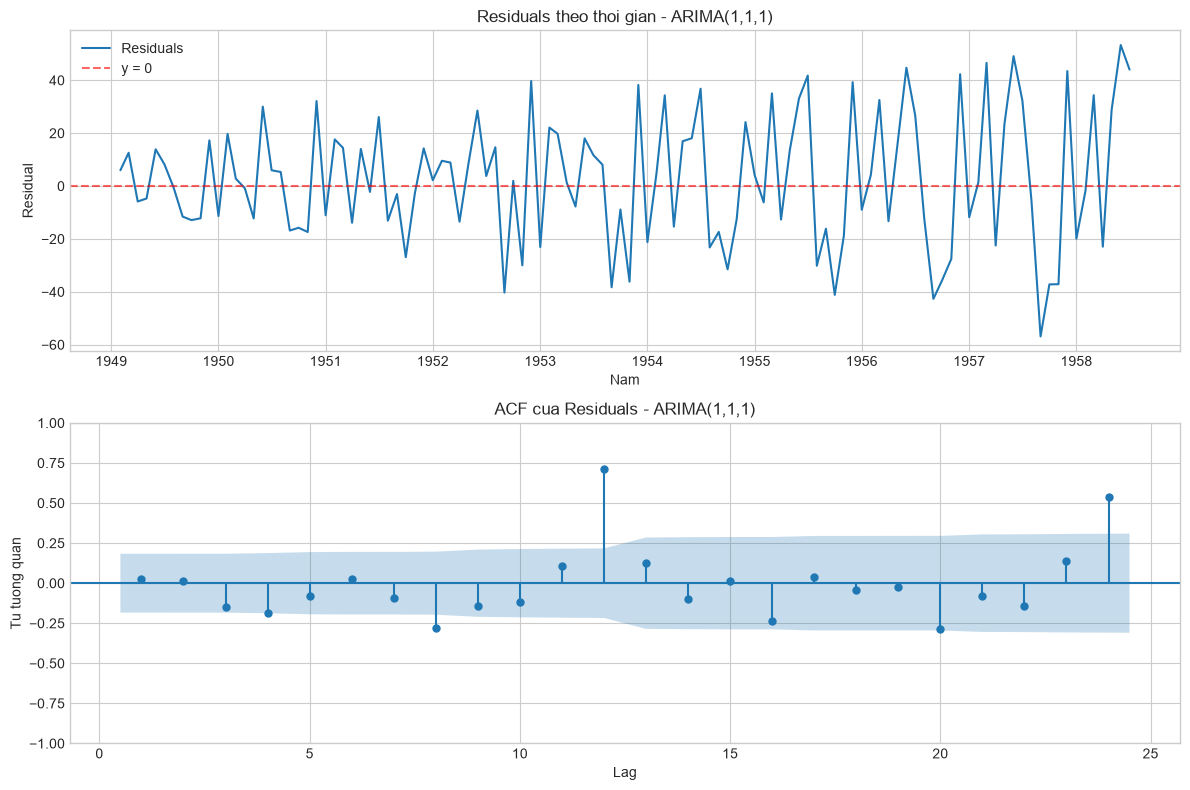

Mean residual : 2.688  (Std = 24.321)
Ljung-Box (lag=24) p-value : 0.0000
=> Con tu tuong quan (khong phai white noise).


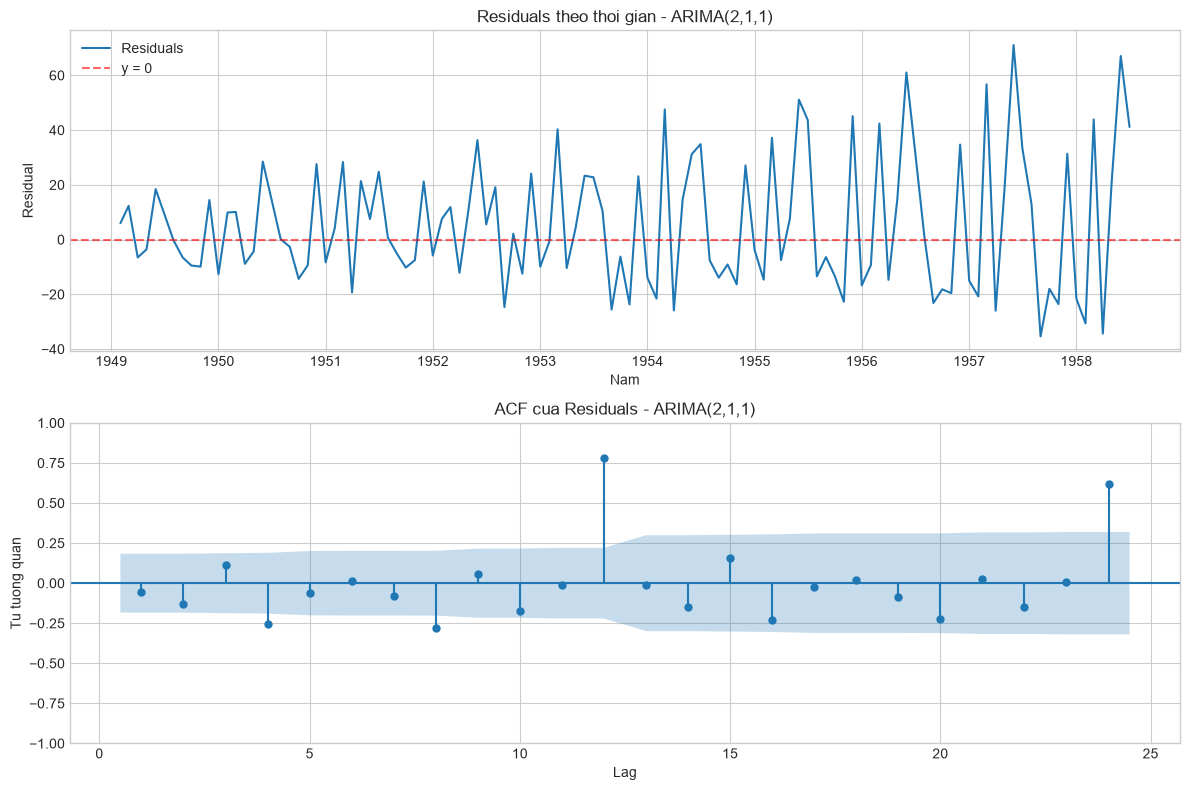

Mean residual : 5.568  (Std = 23.664)
Ljung-Box (lag=24) p-value : 0.0000
=> Con tu tuong quan (khong phai white noise).


In [4]:
diag = {}
for name, order in orders.items():
    tag = name.replace('(', '').replace(')', '').replace(',', '').lower()
    diag[name] = residual_diagnostics(models[name], order, lags=24, title=name,
                                      save_path=str(fig_dir / f'bai5_residuals_{tag}.png'))

**Nhận xét chẩn đoán phần dư:**

| Mô hình | Mean residual | Std | Ljung-Box (lag 24) p-value |
|---|---|---|---|
| ARIMA(1,1,1) | 2.69 | 24.32 | 1.4e-22 |
| ARIMA(2,1,1) | 5.57 | 23.66 | 3.5e-27 |

- **Mean ≈ 0?** Gần bằng 0 so với độ dao động của phần dư (khoảng 11% và 24% độ lệch chuẩn); phần dư của ARIMA(2,1,1) lệch dương hơn một chút.
- **Có tự tương quan không?** **Có, rất rõ.** Ở cả hai mô hình, ACF của phần dư có lag 12 (khoảng 0.71 và 0.78) và lag 24 (khoảng 0.54 và 0.62) vượt hẳn dải tin cậy; các lag 4, 8, 16, 20 (khoảng −0.2 đến −0.3) chạm hoặc vượt nhẹ dải này. Ljung-Box có p-value gần 0 nên bác bỏ H0 "phần dư là white noise".
- Đây là tín hiệu **mùa vụ chu kỳ 12 tháng** mà ARIMA không có thành phần nào để mô tả.

## Bước 4: Dự đoán trên tập Test

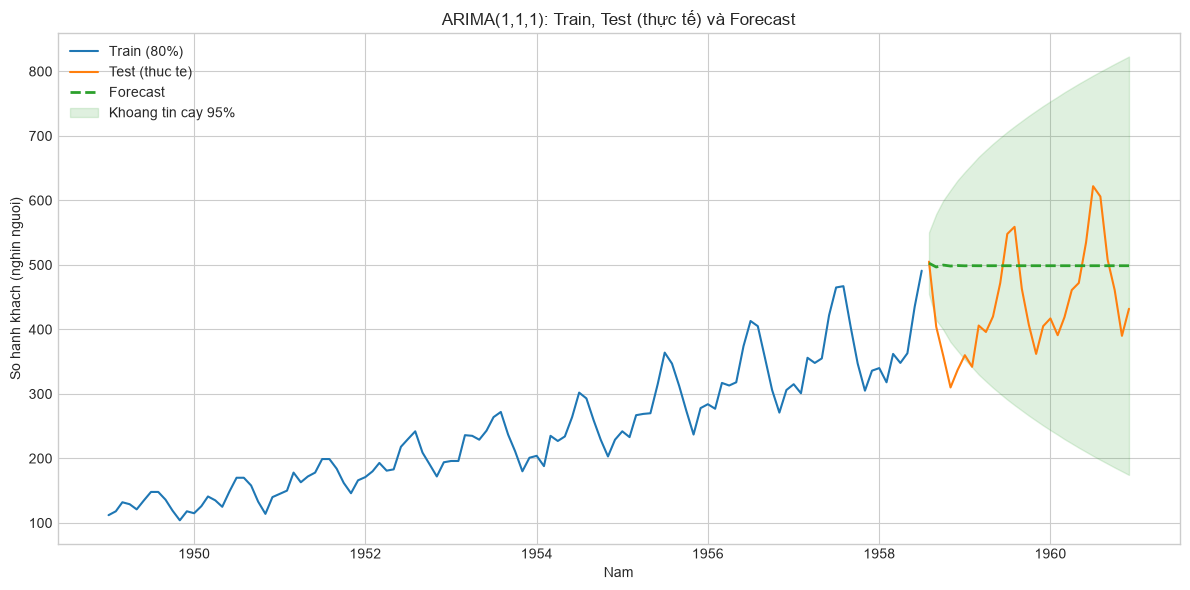

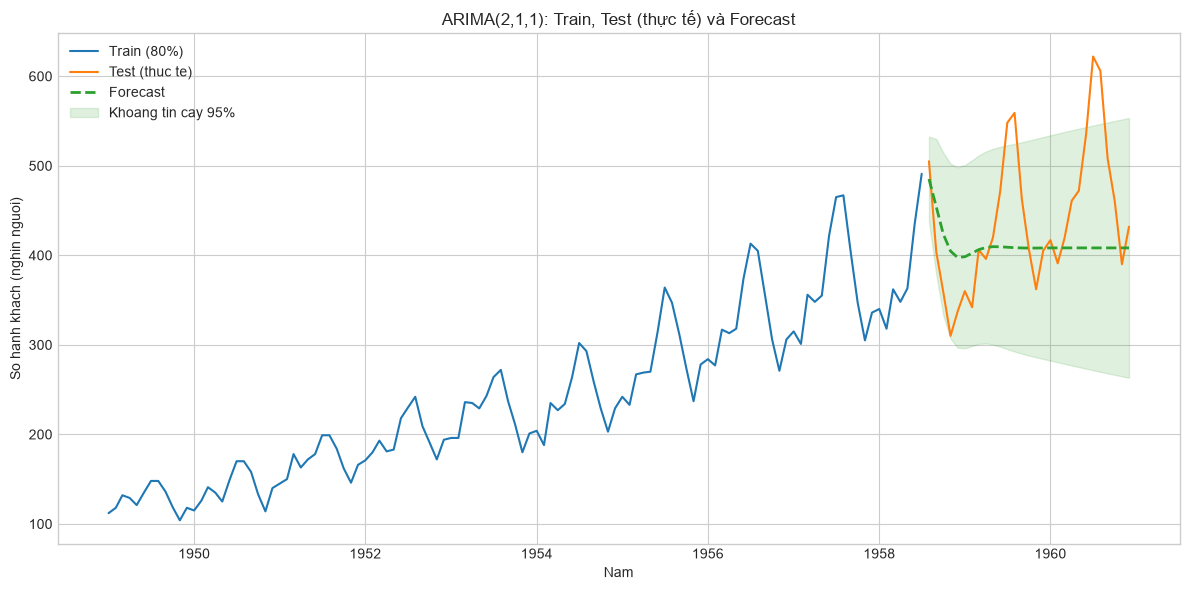

In [5]:
forecasts, conf_ints = {}, {}
for name in orders:
    forecasts[name], conf_ints[name] = forecast_test(models[name], steps=len(test))
    tag = name.replace('(', '').replace(')', '').replace(',', '').lower()
    plot_forecast(train, test, forecasts[name], conf_ints[name],
                  title=f'{name}: Train, Test (thực tế) và Forecast',
                  save_path=str(fig_dir / f'bai5_forecast_{tag}.png'))

**Nhận xét dự báo:**
- **ARIMA(1,1,1)** dự báo gần như **một đường nằm ngang** quanh 497–503, trong khi thực tế Test dao động từ 310 đến 622.
- **ARIMA(2,1,1)** dự báo giảm dần từ khoảng 485 rồi dao động tắt dần quanh mức khoảng 408.
- Cả hai đều **không tái hiện được đỉnh mùa hè lẫn đáy mùa đông**, cũng không đi theo đà tăng của chuỗi. ARIMA(p,1,q) mặc định không có hằng số nên dự báo dài hạn hội tụ về một mức cố định.
- Khoảng tin cậy 95% rất rộng (trung bình khoảng 440 và 234 đơn vị) nên 86% điểm Test nằm trong khoảng này, nhưng đó là do khoảng rộng chứ không phải do dự báo chính xác.

## Bước 5: Đánh giá ARIMA (MAE, RMSE, MAPE, thêm R²)

In [6]:
results = pd.DataFrame({name: evaluate_forecast(test, forecasts[name]) for name in orders}).T
display(results.round(2))

# Các tháng sai lệch lớn nhất (để trả lời câu hỏi 7)
for name in orders:
    err = (test - forecasts[name])
    top = pd.DataFrame({'Thực tế': test, 'Dự báo': forecasts[name].round(1), 'Sai lệch': err.round(1)})
    print(f"\n3 tháng sai lệch lớn nhất - {name}:")
    display(top.loc[err.abs().nlargest(3).index])

print(f"\nTrung bình Test = {test.mean():.1f}; độ lệch chuẩn Test = {test.std():.1f}")

,MAE,RMSE,MAPE (%),R2
"ARIMA(1,1,1)",85.25,97.50,21.29,-0.56
"ARIMA(2,1,1)",60.53,82.62,12.90,-0.12



3 tháng sai lệch lớn nhất - ARIMA(1,1,1):


,Thực tế,Dự báo,Sai lệch
Month,,,
1958-11-01,310,498.2,-188.2
1958-12-01,337,499.0,-162.0
1959-02-01,342,498.8,-156.8



3 tháng sai lệch lớn nhất - ARIMA(2,1,1):


,Thực tế,Dự báo,Sai lệch
Month,,,
1960-07-01,622,408.3,213.7
1960-08-01,606,408.3,197.7
1959-08-01,559,408.5,150.5



Trung bình Test = 440.3; độ lệch chuẩn Test = 79.5


**Nhận xét:**

| Mô hình | MAE | RMSE | MAPE | R² |
|---|---|---|---|---|
| ARIMA(1,1,1) | 85.25 | 97.50 | 21.29% | −0.56 |
| ARIMA(2,1,1) | 60.53 | 82.62 | 12.90% | −0.12 |

R² âm ở cả hai mô hình: dự báo kém hơn việc đoán bằng trung bình của Test. ARIMA(2,1,1) có sai số Test thấp hơn, nhưng không nên dùng Test để chọn mô hình (đó là một dạng rò rỉ). Sự chênh lệch này cũng có vẻ đến từ việc mức dự báo trung bình của ARIMA(2,1,1) tình cờ gần mức trung bình của Test hơn (sai lệch trung bình 28 so với 58) chứ không phải vì nó nắm được cấu trúc mùa vụ. Theo AIC/BIC, hai mô hình tương đương nhau, và cả hai đều thiếu thành phần mùa vụ.

## Trả lời các câu hỏi của Bài 5

**1. Vì sao không được shuffle dữ liệu chuỗi thời gian? Test set dùng để làm gì?**
Các quan sát chuỗi thời gian phụ thuộc vào quá khứ của chúng. Nếu xáo trộn, mô hình sẽ được học từ các tháng nằm *sau* tháng cần dự báo (rò rỉ dữ liệu từ tương lai) và cấu trúc tự tương quan bị phá vỡ. Tập Test là phần dữ liệu mô hình chưa từng thấy, chỉ dùng ở bước cuối để đo khả năng dự báo thực sự trên tương lai.

**2. Ý nghĩa của p, d, q đã chọn?**
- **p** (AR): số giá trị quá khứ của chính chuỗi được dùng để dự báo (p = 1 hoặc 2).
- **d** (I): số lần sai phân để loại xu hướng (d = 1). Lưu ý ở Bài 3, ADF sau sai phân bậc 1 vẫn cho p-value = 0.106 (chưa dừng ở mức 5%) vì còn mùa vụ; chuỗi chỉ dừng khi có thêm sai phân mùa vụ (D = 1, s = 12).
- **q** (MA): số sai số dự báo quá khứ được dùng để hiệu chỉnh (q = 1).

**3. Mô hình có hội tụ không?**
Có. Cả hai mô hình hội tụ (`warnflag = 0`, 15 và 17 vòng lặp), không có cảnh báo hội tụ.

**4. Residuals có phải white noise không?**
Không. Mean gần 0 nhưng ACF của phần dư vượt ngưỡng tin cậy ở nhiều lag (mạnh nhất là lag 12 và 24) và Ljung-Box có p-value ≈ 0 (1.4e-22 và 3.5e-27).

**5. Nếu residuals còn tự tương quan thì điều chỉnh gì?**
Tự tương quan tập trung ở lag 12, 24 nên vấn đề là **mùa vụ**, không phải do thiếu p hoặc q ở lag ngắn. Hướng điều chỉnh: thêm thành phần mùa vụ, tức SARIMA(p,d,q)(P,D,Q)₁₂ với D = 1 (Bài nâng cao). Có thể cân nhắc thêm biến đổi log để ổn định phương sai vì biên độ mùa vụ tăng dần.

**6. Dự đoán có bám sát xu hướng không?**
Không. ARIMA(1,1,1) dự báo gần như phẳng quanh 500, ARIMA(2,1,1) giảm dần và dao động tắt dần quanh khoảng 408, trong khi thực tế vừa tăng vừa có chu kỳ mùa vụ rõ.

**7. Sai lệch lớn nhất xảy ra ở đâu?**
ARIMA(1,1,1): tháng 11/1958 (thực tế 310, dự báo 498, lệch 188). ARIMA(2,1,1): tháng 07/1960 (thực tế 622, dự báo 408, lệch 214). Sai lệch lớn tập trung ở các đỉnh mùa hè và đáy mùa đông vì mô hình không có thành phần mùa vụ.

**8. Chỉ số nào nhạy với outlier nhất?**
**RMSE**, vì bình phương sai số nên các điểm sai lớn được nhân trọng số mạnh. Ở ARIMA(2,1,1), tỉ lệ RMSE/MAE = 1.36 (cao hơn mức 1.14 của ARIMA(1,1,1)) cho thấy sai số tập trung vào một số điểm lớn. MAPE thì nhạy với các điểm có giá trị thực tế nhỏ.

**9. RMSE lớn hay nhỏ nói lên điều gì?**
RMSE = 97.5 và 82.6 (nghìn hành khách) tương ứng khoảng 22% và 19% mức trung bình của Test (440), nên sai số **lớn**. Đáng chú ý, RMSE xấp xỉ độ lệch chuẩn của chính tập Test (79.5) và R² âm (−0.56 và −0.12), tức dự báo chưa tốt hơn việc đoán một hằng số bằng trung bình Test. Nguyên nhân chính là mô hình chưa có thành phần mùa vụ.